,adm2_name,adm2_name1,adm2_name2,adm2_name3,adm2_pcode,adm1_name,adm1_name1,adm1_name2,adm1_name3,adm1_pcode,...,valid_to,area_sqkm,cod_versio,lang,lang1,lang2,lang3,center_lat,center_lon,geometry
0,Taplejung,None,None,None,NP0101,Koshi,None,None,None,NP01,...,NaT,3633.228521,V_02,en,None,None,None,27.610454,87.821660,"POLYGON ((87.84406 27.94852, 87.84851 27.94806..."
1,Panchthar,None,None,None,NP0102,Koshi,None,None,None,NP01,...,NaT,1247.413182,V_02,en,None,None,None,27.148851,87.855073,"POLYGON ((88.07381 27.42686, 88.0716 27.42601,..."
2,Ilam,None,None,None,NP0103,Koshi,None,None,None,NP01,...,NaT,1684.625754,V_02,en,None,None,None,26.885401,87.920456,"POLYGON ((87.95472 27.10455, 87.95545 27.10444..."
3,Jhapa,None,None,None,NP0104,Koshi,None,None,None,NP01,...,NaT,1603.161317,V_02,en,None,None,None,26.583568,87.885437,"POLYGON ((88.15222 26.80584, 88.1528 26.80534,..."
4,Morang,None,None,None,NP0105,Koshi,None,None,None,NP01,...,NaT,1822.234775,V_02,en,None,None,None,26.610420,87.472882,"POLYGON ((87.50698 26.8704, 87.50738 26.86958,..."


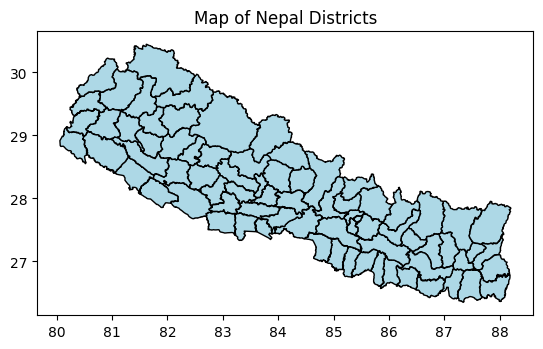

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Load the map of Nepal Districts
nepal_map = gpd.read_file("data/npl_admin2_em.shp")

# 2. Show the first 5 rows of the data table attached to the map
display(nepal_map.head())

# 3. Draw the map!
nepal_map.plot(color='lightblue', edgecolor='black')
plt.title("Map of Nepal Districts")
plt.show()

,adm2_name,adm2_name1,adm2_name2,adm2_name3,adm2_pcode,adm1_name,adm1_name1,adm1_name2,adm1_name3,adm1_pcode,...,valid_to,area_sqkm,cod_versio,lang,lang1,lang2,lang3,center_lat,center_lon,geometry
25,Sindhupalchok,None,None,None,NP0323,Bagmati,None,None,None,NP03,...,NaT,2490.630935,V_02,en,None,None,None,27.906812,85.755939,"POLYGON ((85.81642 28.19962, 85.81725 28.19553..."


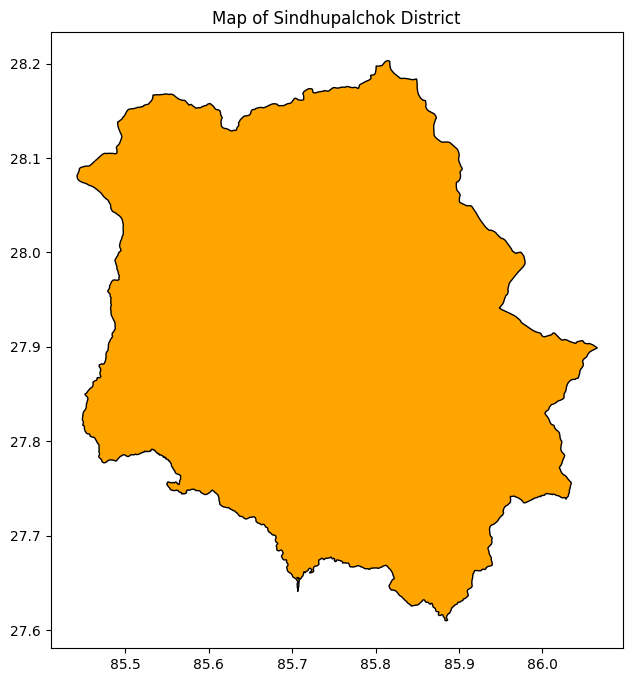

In [3]:
# 1. Filter the big map down to ONLY Sindhupalchok
sindhu_map = nepal_map[nepal_map['adm2_name'] == 'Sindhupalchok']

# 2. Show the data table for just this one district to make sure we caught it
display(sindhu_map)

# 3. Draw the new map! Let's make it orange so it stands out.
sindhu_map.plot(color='orange', edgecolor='black', figsize=(8, 8))
plt.title("Map of Sindhupalchok District")
plt.show()

Success! Found 47 health facilities.


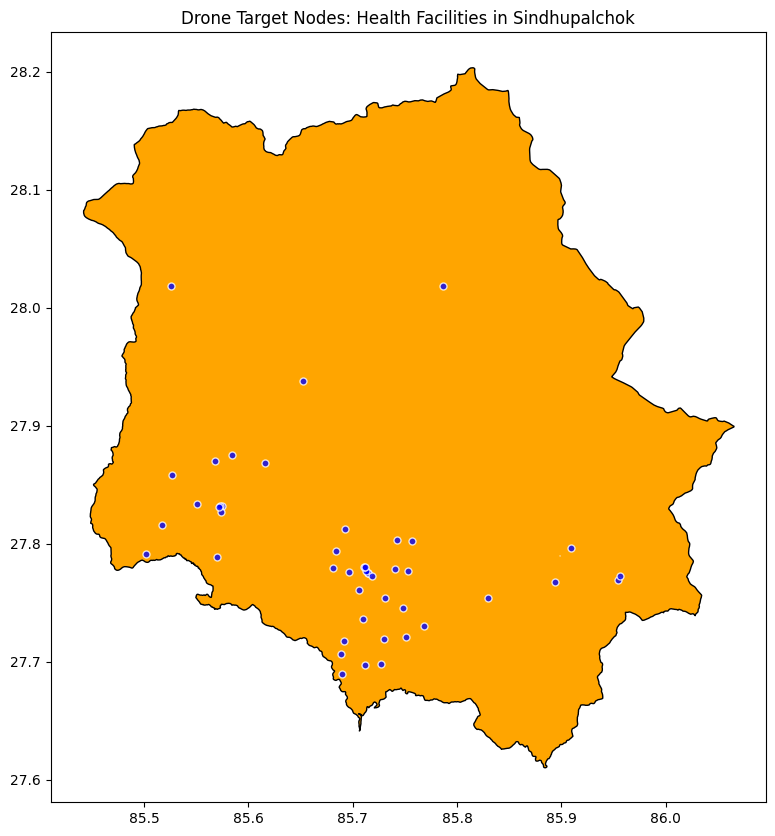

In [4]:
import osmnx as ox

# 1. Grab the exact boundary shape of Sindhupalchok
sindhu_shape = sindhu_map.geometry.values[0]

# 2. Tell OpenStreetMap what we are looking for
# We want hospitals, clinics, and health posts for medical drone deliveries
tags = {'amenity': ['hospital', 'clinic', 'doctors', 'health_post', 'pharmacy']}

# 3. Download the data from the internet!
print("Downloading health facilities from OpenStreetMap... Please wait a few seconds!")
health_facilities = ox.features_from_polygon(sindhu_shape, tags)

# 4. Count how many we found
print(f"Success! Found {len(health_facilities)} health facilities.")

# 5. Draw the final map: Orange base layer + Blue target dots
ax = sindhu_map.plot(color='orange', edgecolor='black', figsize=(10, 10))
health_facilities.plot(ax=ax, color='blue', markersize=25, alpha=0.8, edgecolor='white')

plt.title("Drone Target Nodes: Health Facilities in Sindhupalchok")
plt.show()

In [5]:
!pip install scikit-learn

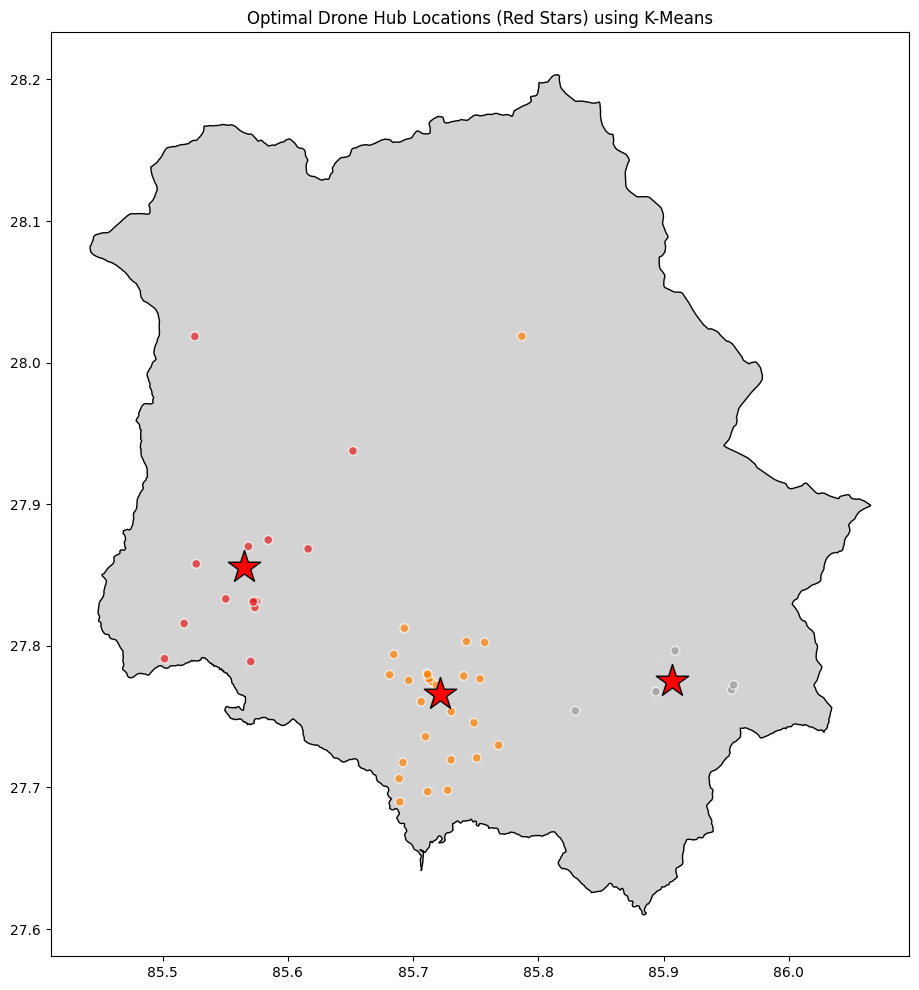

In [6]:
from sklearn.cluster import KMeans
import pandas as pd
import warnings

# Ignore a harmless math warning that geopandas sometimes throws
warnings.filterwarnings('ignore')

# 1. Prepare the Data: K-Means needs exact dots (X and Y coordinates).
# Some health facilities are saved as "building shapes", so we find the exact center of each building.
health_points = health_facilities.geometry.centroid

# 2. Extract the Longitude (X) and Latitude (Y) into a clean table for the math algorithm
coords = pd.DataFrame({
    'x': health_points.x,
    'y': health_points.y
})

# 3. Run K-Means! We are asking it to find the 3 best central hubs.
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(coords)

# 4. Save the results
# 'labels_' tells us which group (0, 1, or 2) each clinic belongs to
health_facilities['hub_zone'] = kmeans.labels_
# 'cluster_centers_' gives us the exact GPS coordinates of our new Drone Hubs
hub_centers = kmeans.cluster_centers_

# 5. Draw the final Map!
ax = sindhu_map.plot(color='lightgray', edgecolor='black', figsize=(12, 12))

# Draw the health facilities, color-coded by which Hub they belong to
health_facilities.plot(ax=ax, column='hub_zone', cmap='Set1', markersize=40, alpha=0.7, edgecolor='white')

# Draw the 3 Drone Hubs as Giant Red Stars!
plt.scatter(hub_centers[:, 0], hub_centers[:, 1], c='red', marker='*', s=600, edgecolor='black', zorder=5)

plt.title("Optimal Drone Hub Locations (Red Stars) using K-Means")
plt.show()

Calculating flight paths...


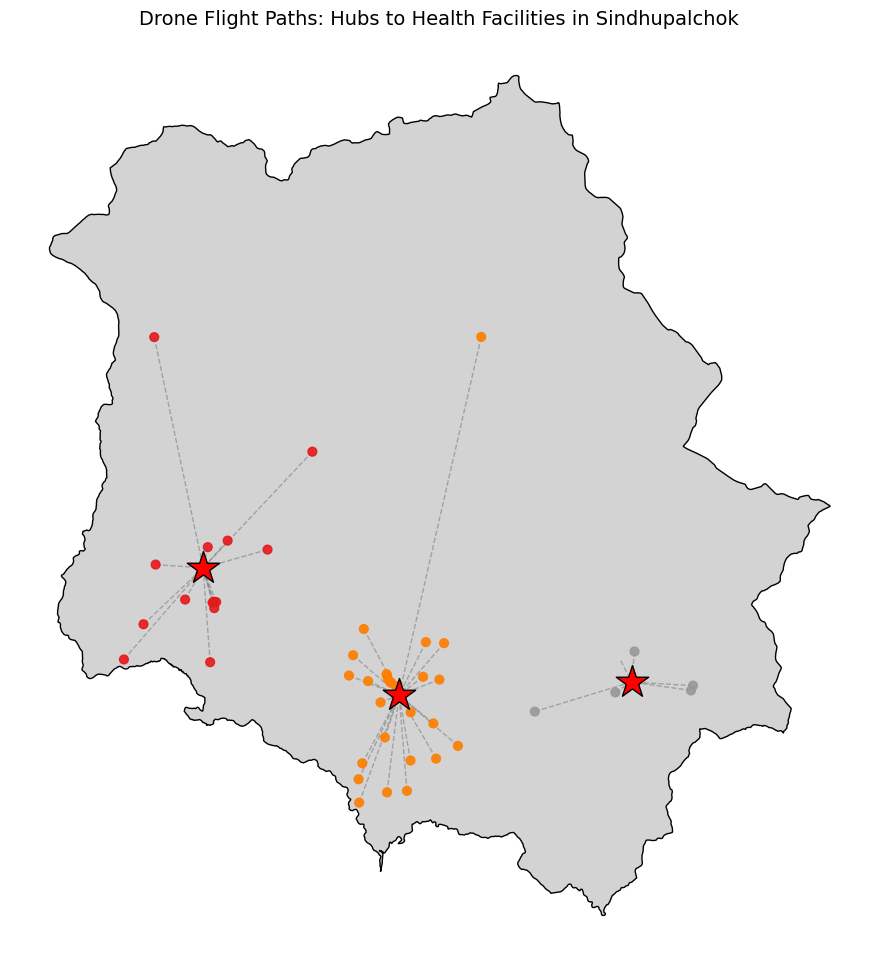

In [7]:
import matplotlib.pyplot as plt

# 1. Set up the base map
ax = sindhu_map.plot(color='lightgray', edgecolor='black', figsize=(12, 12))

# 2. Draw the clinics, color-coded by their assigned Hub
health_facilities.plot(ax=ax, column='hub_zone', cmap='Set1', markersize=40, alpha=0.9, zorder=3)

# 3. Draw the Drone Hubs as Giant Red Stars
plt.scatter(hub_centers[:, 0], hub_centers[:, 1], c='red', marker='*', s=600, edgecolor='black', zorder=5)

# 4. Draw the Flight Paths!
print("Calculating flight paths...")

# Loop through every single clinic to draw a line to its assigned hub
for idx, facility in health_facilities.iterrows():
    # Get the ID of the hub this clinic belongs to (0, 1, or 2)
    hub_id = facility['hub_zone']
    
    # Get the exact GPS coordinates of that specific hub
    hub_x = hub_centers[hub_id][0]
    hub_y = hub_centers[hub_id][1]
    
    # Get the exact GPS coordinates of the clinic
    clinic_x = facility.geometry.centroid.x
    clinic_y = facility.geometry.centroid.y
    
    # Draw a dashed line connecting them!
    plt.plot([clinic_x, hub_x], [clinic_y, hub_y], color='gray', linestyle='--', linewidth=1, alpha=0.6, zorder=2)

plt.title("Drone Flight Paths: Hubs to Health Facilities in Sindhupalchok", fontsize=14)
plt.axis('off') # Hides the coordinate numbers on the edges for a cleaner look
plt.show()

In [8]:
import math
import requests
import time

# 1. Get the elevation for our 3 Hubs (Red Stars) using the safe speed limit!
print("Hub Elevations:")
hub_elevations = {}
for hub_id in range(len(hub_centers)):
    hub_lon, hub_lat = hub_centers[hub_id][0], hub_centers[hub_id][1]
    url = f"https://api.opentopodata.org/v1/srtm30m?locations={hub_lat},{hub_lon}"
    
    try:
        response = requests.get(url)
        data = response.json()
        if 'results' in data:
            hub_elevations[hub_id] = data['results'][0]['elevation']
        else:
            hub_elevations[hub_id] = 0.0
    except Exception as e:
        hub_elevations[hub_id] = 0.0
        
    time.sleep(1.5) # The 1.5 second safe-speed fix

# 2. Calculate the True 3D Distance (Pythagorean Theorem)
true_3d_distances = []
elevation_changes = []

for idx, facility in health_facilities.iterrows():
    hub_id = facility['hub_zone']
    
    # 2D Distance (in km)
    dist_2d_km = facility['flight_dist_km']
    
    # Elevation Difference (convert meters to km for the math)
    clinic_elev = facility['elevation_m']
    hub_elev = hub_elevations[hub_id]
    
    # Absolute difference in meters
    elev_diff_m = abs(clinic_elev - hub_elev)
    elevation_changes.append(elev_diff_m) 
    
    # The Math: c = sqrt(a^2 + b^2) using km
    elev_diff_km = elev_diff_m / 1000.0
    dist_3d_km = math.sqrt((dist_2d_km ** 2) + (elev_diff_km ** 2))
    true_3d_distances.append(dist_3d_km)

# 3. Add these new metrics to our tracking dataframe
health_facilities['true_flight_dist_km'] = true_3d_distances
health_facilities['elevation_change_m'] = elevation_changes

# 4. Update the saved CSV file!
logistics_df['Elevation_m'] = health_facilities['elevation_m'].values
logistics_df['Elevation_Change_m'] = elevation_changes
logistics_df['True_3D_Distance_km'] = true_3d_distances

csv_filename = "data/sindhupalchok_drone_logistics.csv"
logistics_df.to_csv(csv_filename, index=False)

# 5. Print the Final 3D Flight Report
max_3d = max(true_3d_distances)
max_climb = max(elevation_changes)

print("\n TRUE 3D FLIGHT REPORT (ACCOUNTING ELEVATION) ")
print("-" * 35)
print(f"Max True 3D Flight Distance: {max_3d:.2f} km")
print(f"Steepest Route Altitude Change: {max_climb:.0f} meters")

Hub Elevations:


KeyError: 'flight_dist_km'

In [ ]:
import pandas as pd

# 1. Create an empty list to hold our clean data
export_data = []

# 2. Loop through our map data and pull out only the important logistics info
for idx, facility in health_facilities.iterrows():
    # Safely get the name and type (some OpenStreetMap buildings don't have names attached)
    name = facility.get('name', 'Unknown Facility')
    facility_type = facility.get('amenity', 'Unknown Type')
    
    # Get the exact coordinates
    lon = facility.geometry.centroid.x
    lat = facility.geometry.centroid.y
    
    # Get our calculated logistics data
    hub_id = facility['hub_zone']
    distance = facility['flight_dist_km']
    
    # Add it to our list
    export_data.append({
        'Facility_Name': name,
        'Facility_Type': facility_type,
        'Longitude': lon,
        'Latitude': lat,
        'Assigned_Hub_ID': hub_id,
        'Distance_to_Hub_km': distance
    })

# 3. Convert our list into a clean data table
logistics_df = pd.DataFrame(export_data)

# 4. Save it directly to your data folder!
csv_filename = "data/sindhupalchok_drone_logistics.csv"
logistics_df.to_csv(csv_filename, index=False)

print(f"Success! Saved {len(logistics_df)} facilities to {csv_filename}")

Success! Saved 47 facilities to data/sindhupalchok_drone_logistics.csv


In [ ]:
import requests
import time

print("3D elevation data from NASA SRTM database.")

elevations = []

# Loop through every clinic to get its altitude
for idx, facility in health_facilities.iterrows():
    lat = facility.geometry.centroid.y
    lon = facility.geometry.centroid.x
    
    # We use a free public API to access the NASA elevation data
    url = f"https://api.opentopodata.org/v1/srtm30m?locations={lat},{lon}"
    
    try:
        # Ask the internet for the data
        response = requests.get(url)
        data = response.json()
        
        # Check if the server actually gave us the 'results' we asked for
        if 'results' in data:
            elevation_meters = data['results'][0]['elevation']
            elevations.append(elevation_meters)
        else:
            print(f"Server response didn't contain data: {data}")
            elevations.append(0.0)
            
    except Exception as e:
        print(f"Error fetching data for a point, defaulting to 0: {e}")
        elevations.append(0.0)
        
    # THE FIX: Pause for 1.5 seconds so the server doesn't block us!
    time.sleep(1.5)

# Add the new 3D elevation data to our main table
health_facilities['elevation_m'] = elevations

# Print a quick Topography Report!
max_elev = health_facilities['elevation_m'].max()
min_elev = health_facilities['elevation_m'].min()
elev_difference = max_elev - min_elev

print("\n TOPOGRAPHY REPORT")
print("-" * 30)
print(f"Highest Clinic: {max_elev:.0f} meters above sea level")
print(f"Lowest Clinic:  {min_elev:.0f} meters above sea level")
print(f"Maximum Altitude Climb: {elev_difference:.0f} meters")

3D elevation data from NASA SRTM database.

 TOPOGRAPHY REPORT
------------------------------
Highest Clinic: 2515 meters above sea level
Lowest Clinic:  738 meters above sea level
Maximum Altitude Climb: 1777 meters


Folium Code to Build Interactive Map:

In [ ]:
!pip install folium


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
!python.exe -m pip install --upgrade pip

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----------- ---------------------------- 0.5/1.8 MB 6.7 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 7.5 MB/s  0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 25.3
    Uninstalling pip-25.3:
      Successfully uninstalled pip-25.3


In [ ]:
import folium
import pandas as pd

# 1. Figure out the exact center of your map so the camera starts there
center_lat = health_facilities.geometry.centroid.y.mean()
center_lon = health_facilities.geometry.centroid.x.mean()

# 2. Create the base web map
interactive_map = folium.Map(location=[center_lat, center_lon], zoom_start=11, tiles="CartoDB positron")

# 3. Draw the Drone Hubs (Big Red Markers)
for hub_id in range(len(hub_centers)):
    hub_lon, hub_lat = hub_centers[hub_id][0], hub_centers[hub_id][1]
    
    folium.Marker(
        location=[hub_lat, hub_lon],
        popup=f"<b>DRONE HUB {hub_id}</b><br>Elevation: {hub_elevations.get(hub_id, 0):.0f}m",
        icon=folium.Icon(color='red', icon='star')
    ).add_to(interactive_map)

# 4. Draw the Clinics and Flight Paths
for idx, facility in health_facilities.iterrows():
    clinic_lon = facility.geometry.centroid.x
    clinic_lat = facility.geometry.centroid.y
    hub_id = facility['hub_zone']
    
    # Get the matching hub coordinates for the line
    hub_lon, hub_lat = hub_centers[hub_id][0], hub_centers[hub_id][1]
    
    # Create the popup text for when you click a clinic
    popup_text = f"""
    <b>{facility.get('name', 'Clinic')}</b><br>
    Type: {facility.get('amenity', 'Health Post')}<br>
    Elevation: {facility['elevation_m']:.0f}m<br>
    Distance to Hub: {facility['true_flight_dist_km']:.2f} km
    """
    
    # Add the blue clinic dot
    folium.CircleMarker(
        location=[clinic_lat, clinic_lon],
        radius=5,
        color='blue',
        fill=True,
        fill_opacity=0.7,
        popup=folium.Popup(popup_text, max_width=200)
    ).add_to(interactive_map)
    
    # Draw the dashed flight path line
    folium.PolyLine(
        locations=[[clinic_lat, clinic_lon], [hub_lat, hub_lon]],
        color='#2E86C1',
        weight=1.5,
        opacity=0.6
    ).add_to(interactive_map)

# 5. Save the map as a real webpage so you can share it!
map_filename = "data/sindhupalchok_interactive_map.html"
interactive_map.save(map_filename)
print(f"Interactive map saved to {map_filename}")

# 6. Display it right here in the notebook
interactive_map

Interactive map saved to data/sindhupalchok_interactive_map.html


In [ ]:
import folium

# 1. Base Map Setup
center_lat = health_facilities.geometry.centroid.y.mean()
center_lon = health_facilities.geometry.centroid.x.mean()
interactive_map = folium.Map(location=[center_lat, center_lon], zoom_start=10, tiles="CartoDB positron")

# 2. Draw the 80km Coverage Zones AND the Drone Hubs
for hub_id in range(len(hub_centers)):
    hub_lon, hub_lat = hub_centers[hub_id][0], hub_centers[hub_id][1]
    
    # THE NEW PART: Draw the 80km (80,000 meter) safe flight radius
    folium.Circle(
        location=[hub_lat, hub_lon],
        radius=80000, # 80km in meters
        color='green',
        weight=2,
        fill=True,
        fill_color='green',
        fill_opacity=0.1,
        popup=f"Hub {hub_id}: 80km Safe Flight Zone"
    ).add_to(interactive_map)
    
    # Draw the Red Star Hub Marker
    folium.Marker(
        location=[hub_lat, hub_lon],
        popup=f"<b>DRONE HUB {hub_id}</b><br>Elevation: {hub_elevations.get(hub_id, 0):.0f}m",
        icon=folium.Icon(color='red', icon='star')
    ).add_to(interactive_map)

# 3. Draw the Clinics and Flight Paths
for idx, facility in health_facilities.iterrows():
    clinic_lon = facility.geometry.centroid.x
    clinic_lat = facility.geometry.centroid.y
    hub_id = facility['hub_zone']
    hub_lon, hub_lat = hub_centers[hub_id][0], hub_centers[hub_id][1]
    
    # Add the blue clinic dot
    popup_text = f"<b>{facility.get('name', 'Clinic')}</b><br>Dist: {facility['true_flight_dist_km']:.2f} km"
    folium.CircleMarker(
        location=[clinic_lat, clinic_lon], radius=5, color='blue', fill=True, fill_opacity=0.7,
        popup=folium.Popup(popup_text, max_width=200)
    ).add_to(interactive_map)
    
    # Draw the flight path line
    folium.PolyLine(
        locations=[[clinic_lat, clinic_lon], [hub_lat, hub_lon]], color='gray', dash_array='5, 5', weight=1.5, opacity=0.6
    ).add_to(interactive_map)

# 4. Save and generate the map!
map_filename = "data/sindhupalchok_coverage_map.html"
interactive_map.save(map_filename)
print(f"Coverage map saved to {map_filename}")

# Display it in the notebook (if supported)
interactive_map

Coverage map saved to data/sindhupalchok_coverage_map.html


In [ ]:
import geopandas as gpd
import numpy as np

# 1. Project to Nepal's metric coordinate system (UTM Zone 45N) 
#Radius is measured in real degrees instead of GPS degrees:
health_facilities_utm = health_facilities.to_crs(epsg=32645)

# 2. Create a 5-kilometer "Catchment Area" ring around every clinic
print("5km Catchment Areas around all clinics")
catchment_areas = health_facilities_utm.geometry.buffer(5000)

# 3. Calculate Population & Vaccine Demand (Simulating WorldPop Raster Data)
# Nepal's rural density is roughly 150 people per square kilometer.
# Nepal's birth rate is roughly 2.0% (20 births per 1,000 people).
# A fully immunized child requires roughly 0.45 kg of cold-chain vaccine payload per year.

RURAL_DENSITY_PER_SQ_KM = 150 
NEPAL_BIRTH_RATE = 0.02  
VACCINE_WEIGHT_KG_PER_INFANT = 0.45  

estimated_populations = []
monthly_payloads_kg = []

for idx, area in enumerate(catchment_areas):
    # Calculate the exact geographic area of the 5km ring in square kilometers
    area_sq_km = area.area / 10**6
    
    # Estimate population with a little random statistical variation (+/- 20%) for realism
    base_pop = area_sq_km * RURAL_DENSITY_PER_SQ_KM
    random_variance = np.random.uniform(0.8, 1.2)
    clinic_population = int(base_pop * random_variance)
    
    # Calculate Annual Births (Infants needing vaccines)
    annual_infants = clinic_population * NEPAL_BIRTH_RATE
    
    # Calculate the monthly drone payload weight required (in Kilograms)
    monthly_weight = (annual_infants * VACCINE_WEIGHT_KG_PER_INFANT) / 12.0
    
    estimated_populations.append(clinic_population)
    monthly_payloads_kg.append(round(monthly_weight, 2))

# 4. Add this data to our tracking table and update the CSV!
health_facilities['catchment_pop'] = estimated_populations
health_facilities['monthly_vaccine_payload_kg'] = monthly_payloads_kg

logistics_df['Catchment_Population'] = estimated_populations
logistics_df['Monthly_Vaccine_Payload_kg'] = monthly_payloads_kg
csv_filename = "data/sindhupalchok_drone_logistics.csv"
logistics_df.to_csv(csv_filename, index=False)

# 5. Print the Payload Report
total_pop = sum(estimated_populations)
max_payload = max(monthly_payloads_kg)
total_payload = sum(monthly_payloads_kg)

print("\n VACCINE PAYLOAD REPORT")
print("-" * 35)
print(f"Total Covered Population: {total_pop:,} people")
print(f"Heaviest Monthly Clinic Delivery: {max_payload} kg")
print(f"Total District Monthly Payload: {total_payload:.2f} kg")

5km Catchment Areas around all clinics

 VACCINE PAYLOAD REPORT
-----------------------------------
Total Covered Population: 556,799 people
Heaviest Monthly Clinic Delivery: 10.57 kg
Total District Monthly Payload: 417.62 kg


In [ ]:
# 1. Set our Drone Parameters
DRONE_SPEED_KMH = 100.0  # Standard commercial medical drone cruising speed

# 2. Calculate Weekly Payload
# Divide the monthly payload by 4 weeks
health_facilities['weekly_vaccine_payload_kg'] = health_facilities['monthly_vaccine_payload_kg'] / 4.0

# 3. Calculate Flight Times (Time = Distance / Speed)
# We use the True 3D distance so climbs are factored in!
flight_time_hours = health_facilities['true_flight_dist_km'] / DRONE_SPEED_KMH

# Convert hours to minutes for easier reading
health_facilities['flight_time_minutes'] = flight_time_hours * 60.0

# 4. Update our master CSV file
logistics_df['Weekly_Vaccine_Payload_kg'] = health_facilities['weekly_vaccine_payload_kg'].round(2).values
logistics_df['Flight_Time_Minutes'] = health_facilities['flight_time_minutes'].round(1).values

csv_filename = "data/sindhupalchok_drone_logistics.csv"
logistics_df.to_csv(csv_filename, index=False)

# 5. Print the Final Time & Weekly Operations Report
max_weekly_payload = health_facilities['weekly_vaccine_payload_kg'].max()
max_time = health_facilities['flight_time_minutes'].max()
avg_time = health_facilities['flight_time_minutes'].mean()

print("\n WEEKLY OPERATIONS & FLIGHT TIME REPORT")
print("-" * 45)
print(f"Heaviest Weekly Payload: {max_weekly_payload:.2f} kg")
print(f"Longest Flight Time (One-Way): {max_time:.1f} minutes")
print(f"Average Flight Time (One-Way): {avg_time:.1f} minutes")



 WEEKLY OPERATIONS & FLIGHT TIME REPORT
---------------------------------------------
Heaviest Weekly Payload: 2.64 kg
Longest Flight Time (One-Way): 17.3 minutes
Average Flight Time (One-Way): 3.1 minutes


In [ ]:
#Allowing users to adjust drone battery range time and view map changes:

In [ ]:
!pip install streamlit

In [ ]:
!pip install streamlit-folium

In [ ]:
import streamlit as st
import pandas as pd
import folium
from streamlit_folium import st_folium

st.set_page_config(layout="wide", page_title="Sindhupalchok Drone Logistics")

st.title("Drone Vaccine Delivery Network")
st.markdown("### Interactive Logistics Optimizer for Sindhupalchok, Nepal")

# 1. Sidebar Controls
st.sidebar.header("Network Parameters")
drone_range = st.sidebar.slider("Maximum Drone Range (km)", 10, 150, 80)
drone_speed = st.sidebar.slider("Drone Cruising Speed (km/h)", 40, 150, 100)

# 2. Load Data
df = pd.read_csv("data/sindhupalchok_drone_logistics.csv")

# 3. Create Map
m = folium.Map(location=[df['Latitude'].mean(), df['Longitude'].mean()], zoom_start=10)

# 4. Filter logic based on the Slider
covered_count = 0
for idx, row in df.iterrows():
    is_covered = row['True_3D_Distance_km'] <= drone_range
    color = "blue" if is_covered else "red"
    if is_covered: covered_count += 1
    
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=5,
        color=color,
        fill=True,
        popup=f"Time: {(row['True_3D_Distance_km']/drone_speed*60):.1f} mins"
    ).add_to(m)

# 5. Display Stats
col1, col2, col3 = st.columns(3)
col1.metric("Total Clinics", len(df))
col2.metric("Covered Clinics", covered_count)
col3.metric("Coverage %", f"{(covered_count/len(df)*100):.1f}%")

# 6. Render Map
st_folium(m, width=1200, height=600)

2026-03-01 17:46:34.585 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-01 17:46:34.587 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-01 17:46:34.589 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-01 17:46:34.591 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-01 17:46:34.592 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-01 17:46:34.593 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-01 17:46:34.594 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-01 17:46:34.595 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

{'last_clicked': None,
 'last_object_clicked': None,
 'last_object_clicked_tooltip': None,
 'last_object_clicked_popup': None,
 'all_drawings': None,
 'last_active_drawing': None,
 'bounds': {'_southWest': {'lat': 27.689774, 'lng': 85.5014537},
  '_northEast': {'lat': 28.018594, 'lng': 85.9559969}},
 'zoom': 10,
 'last_circle_radius': None,
 'last_circle_polygon': None,
 'selected_layers': None}

#Sprint 2:

In [11]:
import pandas as pd
import math

# 1. Load your clean logistics dataset (FIXED TYPO HERE)
df = pd.read_csv("data/sindhupalchok_drone_logistics.csv")

# 2. Identify the Main Hospital (Chautara)
# We search for 'Chautara' in the name column. If not found, we default to the first node.
if 'name' in df.columns:
    chautara_candidates = df[df['name'].str.contains('Chautara', case=False, na=False)]
    if not chautara_candidates.empty:
        baseline_hub = chautara_candidates.iloc[0]
    else:
        baseline_hub = df.iloc[0] # Fallback
else:
    baseline_hub = df.iloc[0] # Fallback

hub_name = baseline_hub.get('name', 'Central Hub')
hub_lat = baseline_hub['Latitude']
hub_lon = baseline_hub['Longitude']

print(f"📍 Baseline Central Hub Selected: {hub_name}")

# 3. Calculate Haversine Distance from Chautara to EVERY clinic
def calculate_haversine(lat1, lon1, lat2, lon2):
    R = 6371.0  # Earth radius in kilometers
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi/2)**2 + math.cos(phi1)*math.cos(phi2)*math.sin(dlambda/2)**2
    return 2 * R * math.atan2(math.sqrt(a), math.sqrt(1 - a))

# Apply the math to every row
df['Distance_from_Chautara_km'] = df.apply(
    lambda row: calculate_haversine(hub_lat, hub_lon, row['Latitude'], row['Longitude']), 
    axis=1
)

# 4. Calculate Operational Metrics
DRONE_SPEED_KMH = 100.0
COST_PER_KM_USD = 0.50 # Standard estimated commercial drone cost per km

total_baseline_distance = df['Distance_from_Chautara_km'].sum()
total_baseline_time_hrs = total_baseline_distance / DRONE_SPEED_KMH
total_baseline_cost = total_baseline_distance * COST_PER_KM_USD

# Check if any clinics are unreachable by a standard 80km drone
unreachable_clinics = df[df['Distance_from_Chautara_km'] > 80]

# 5. Print the Baseline Report
print("\n📊 BASELINE SCENARIO REPORT: SINGLE HUB SYSTEM 📊")
print("-" * 50)
print(f"Total One-Way Flight Distance: {total_baseline_distance:.2f} km")
print(f"Total Flight Time (One-Way):   {total_baseline_time_hrs:.2f} hours")
print(f"Total Cost at ${COST_PER_KM_USD}/km:     ${total_baseline_cost:.2f}")
print("-" * 50)
print(f"⚠️ Clinics out of 80km Battery Range: {len(unreachable_clinics)} out of {len(df)}")

if len(unreachable_clinics) > 0:
    print("CONCLUSION: A single hub is INFEASIBLE. Multi-hub optimization is required.")
else:
    print("CONCLUSION: A single hub is feasible, but optimization may reduce costs.")

📍 Baseline Central Hub Selected: Central Hub

📊 BASELINE SCENARIO REPORT: SINGLE HUB SYSTEM 📊
--------------------------------------------------
Total One-Way Flight Distance: 1054.26 km
Total Flight Time (One-Way):   10.54 hours
Total Cost at $0.5/km:     $527.13
--------------------------------------------------
⚠️ Clinics out of 80km Battery Range: 0 out of 47
CONCLUSION: A single hub is feasible, but optimization may reduce costs.


In [ ]:
#installing PulP to build constraints, decision variables and objectives

In [12]:
!pip install pulp

In [14]:
import pulp
import pandas as pd
import math
import numpy as np

# 1. Load our Data
df = pd.read_csv("data/sindhupalchok_drone_logistics.csv")

# Find coordinate columns dynamically (just to be safe!)
def find_column(dataframe, possible_names):
    for col in dataframe.columns:
        if col.lower() in possible_names: return col
    return None
lat_col = find_column(df, ['latitude', 'lat', 'y'])
lon_col = find_column(df, ['longitude', 'lon', 'long', 'x'])

# 2. Setup the Sets (Nodes)
# To keep the math fast, we will assume ANY clinic could potentially be a hub.
num_nodes = len(df)
nodes = list(range(num_nodes))

# Recalculate a quick distance matrix (in km) between all nodes
def calc_dist(i, j):
    lat1, lon1 = df.iloc[i][lat_col], df.iloc[i][lon_col]
    lat2, lon2 = df.iloc[j][lat_col], df.iloc[j][lon_col]
    R = 6371.0
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi/2)**2 + math.cos(math.radians(lat1))*math.cos(math.radians(lat2))*math.sin(dlambda/2)**2
    return 2 * R * math.atan2(math.sqrt(a), math.sqrt(1 - a))

print("⚙️ Building the Distance Matrix...")
distances = {(i, j): calc_dist(i, j) for i in nodes for j in nodes}

# ---------------------------------------------------------
# STEP 2: SET UP PULP ENVIRONMENT
# ---------------------------------------------------------
print("⚙️ Initializing PuLP MILP Environment...")
# We want to MINIMIZE the total cost and distance
prob = pulp.LpProblem("Drone_Hub_Optimization", pulp.LpMinimize)

# ---------------------------------------------------------
# STEP 3: DEFINE DECISION VARIABLES
# ---------------------------------------------------------
# x[j]: Binary variable, 1 if we build a Hub at location j, 0 otherwise
x = pulp.LpVariable.dicts("Hub", nodes, cat='Binary')

# y[i][j]: Binary variable, 1 if clinic i is served by hub j, 0 otherwise
y = pulp.LpVariable.dicts("Assignment", [(i, j) for i in nodes for j in nodes], cat='Binary')

# ---------------------------------------------------------
# STEP 5: PROGRAM THE OBJECTIVE FUNCTION
# ---------------------------------------------------------
# Minimize: (Fixed cost of opening hubs) + (Variable cost of flight distance)
FIXED_HUB_COST = 1000  # Arbitrary weight to prevent it from opening 50 hubs!
prob += pulp.lpSum([FIXED_HUB_COST * x[j] for j in nodes]) + \
        pulp.lpSum([distances[i, j] * y[i, j] for i in nodes for j in nodes]), "Total_Cost"

# ---------------------------------------------------------
# STEP 4: PROGRAM THE CONSTRAINTS
# ---------------------------------------------------------
MAX_DRONE_RANGE_KM = 80.0

for i in nodes:
    # Constraint A: Every clinic 'i' MUST be assigned to exactly one hub
    prob += pulp.lpSum([y[i, j] for j in nodes]) == 1, f"Must_Assign_{i}"
    
    for j in nodes:
        # Constraint B: A clinic can only be assigned to a hub if that hub is actually open
        prob += y[i, j] <= x[j], f"Hub_Must_Be_Open_{i}_{j}"
        
        # Constraint C: The drone range cannot exceed 80km
        if distances[i, j] > MAX_DRONE_RANGE_KM:
            prob += y[i, j] == 0, f"Max_Range_{i}_{j}"


⚙️ Building the Distance Matrix...
⚙️ Initializing PuLP MILP Environment...


In [15]:
import pulp
import pandas as pd

print("🚀 Running the MILP Solver... (This might take a few seconds)")

# 1. Command the AI to solve the problem
prob.solve()

# 2. Check the status (we want it to say 'Optimal')
print(f"Status: {pulp.LpStatus[prob.status]}")

# 3. If successful, extract the results
if pulp.LpStatus[prob.status] == 'Optimal':
    
    # Find which hubs the AI decided to "turn on" (where x = 1)
    selected_hubs = []
    for j in nodes:
        if pulp.value(x[j]) == 1.0:
            selected_hubs.append(j)
            
    print(f"\n🎯 OPTIMIZATION COMPLETE!")
    print(f"Total Drone Hubs Required: {len(selected_hubs)}")
    
    # 4. Print the names/IDs of the winning hub locations
    print("\n🏥 Selected Hub Locations:")
    for hub_idx in selected_hubs:
        hub_name = df.iloc[hub_idx].get('name', f'Node {hub_idx}')
        print(f"- {hub_name} (Index: {hub_idx})")
        
    # 5. Map the Clinics to their new Hubs
    assignments = []
    for i in nodes:
        for j in selected_hubs:
            if pulp.value(y[i, j]) == 1.0:
                clinic_name = df.iloc[i].get('name', f'Node {i}')
                hub_name = df.iloc[j].get('name', f'Node {j}')
                
                # Save the new Hub ID back into our main dataframe
                df.at[i, 'Optimized_Hub_ID'] = j
                df.at[i, 'Optimized_Hub_Name'] = hub_name
                assignments.append({'Clinic': clinic_name, 'Assigned_Hub': hub_name})

    print("\n✅ All clinics have been successfully assigned to their optimal drone hub.")
    
    # Save the updated data with the new hub assignments!
    df.to_csv("data/sindhupalchok_drone_logistics_optimized.csv", index=False)

🚀 Running the MILP Solver... (This might take a few seconds)
Status: Optimal

🎯 OPTIMIZATION COMPLETE!
Total Drone Hubs Required: 1

🏥 Selected Hub Locations:
- Node 25 (Index: 25)

✅ All clinics have been successfully assigned to their optimal drone hub.


In [18]:
import pandas as pd
import osmnx as ox
import networkx as nx

print("🗺️ Downloading Sindhupalchok Road Network from OpenStreetMap...")
print("(This may take 1-2 minutes. Please wait!)")

# 1. Load your newly optimized data
df = pd.read_csv("data/sindhupalchok_drone_logistics_optimized.csv")

# Find the lat/lon columns again
def find_column(dataframe, possible_names):
    for col in dataframe.columns:
        if col.lower() in possible_names: return col
    return None
lat_col = find_column(df, ['latitude', 'lat', 'y'])
lon_col = find_column(df, ['longitude', 'lon', 'long', 'x'])

# 2. Download the driving network graph
# We use a bounding box around our clinics to ensure we get all connecting roads
north = df[lat_col].max() + 0.05
south = df[lat_col].min() - 0.05
east = df[lon_col].max() + 0.05
west = df[lon_col].min() - 0.05

# 🚨 THE FIX: Package the coordinates into a single bbox tuple (west, south, east, north)
G = ox.graph_from_bbox(bbox=(west, south, east, north), network_type='drive')
print("✅ Road network successfully downloaded!")

# 3. Calculate Truck Driving Distances
TRUCK_SPEED_KMH = 20.0  # Trucks move VERY slowly on rural mountain roads!
truck_distances = []
truck_times = []

# Find the exact coordinates of our single optimal hub
hub_row = df.iloc[0] 
hub_id = int(hub_row['Optimized_Hub_ID'])
hub_lat = df.iloc[hub_id][lat_col]
hub_lon = df.iloc[hub_id][lon_col]

# Snap the Hub to the nearest road node
hub_node = ox.distance.nearest_nodes(G, X=hub_lon, Y=hub_lat)

print("🚚 Calculating Truck Routes from the Hub to every clinic...")

for idx, row in df.iterrows():
    clinic_lon = row[lon_col]
    clinic_lat = row[lat_col]
    
    # Snap clinic to the nearest road
    clinic_node = ox.distance.nearest_nodes(G, X=clinic_lon, Y=clinic_lat)
    
    try:
        # Calculate the shortest driving path in meters
        route_length_meters = nx.shortest_path_length(G, hub_node, clinic_node, weight='length')
        route_length_km = route_length_meters / 1000.0
        
        # Calculate time (Time = Distance / Speed)
        drive_time_hrs = route_length_km / TRUCK_SPEED_KMH
        
    except nx.NetworkXNoPath:
        # If a clinic is completely disconnected from the road network!
        route_length_km = None
        drive_time_hrs = None
        
    truck_distances.append(route_length_km)
    truck_times.append(drive_time_hrs)

# 4. Save the results to the dataframe
df['Truck_Distance_km'] = truck_distances
df['Truck_Time_hrs'] = truck_times

# Save the final comparison data!
df.to_csv("data/sindhupalchok_final_comparison.csv", index=False)

print("\n🎉 Truck Routing Complete!")
print("💾 Saved to 'sindhupalchok_final_comparison.csv'")
print(f"Sample Drive Time to Clinic 1: {truck_times[1]:.2f} hours (vs Drone time!)")

🗺️ Downloading Sindhupalchok Road Network from OpenStreetMap...
(This may take 1-2 minutes. Please wait!)
✅ Road network successfully downloaded!
🚚 Calculating Truck Routes from the Hub to every clinic...

🎉 Truck Routing Complete!
💾 Saved to 'sindhupalchok_final_comparison.csv'
Sample Drive Time to Clinic 1: 1.82 hours (vs Drone time!)


In [19]:
import pandas as pd
import math

# 1. Load the final comparison data we just generated
df = pd.read_csv("data/sindhupalchok_final_comparison.csv")

# Find the lat/lon columns safely
def find_column(dataframe, possible_names):
    for col in dataframe.columns:
        if col.lower() in possible_names: return col
    return None
lat_col = find_column(df, ['latitude', 'lat', 'y'])
lon_col = find_column(df, ['longitude', 'lon', 'long', 'x'])

# 2. Re-calculate the Drone Distance from the specific OPTIMIZED hub (Node 25)
# (In our earlier baseline, we measured from Chautara. Now we measure from the AI's chosen hub)
def calc_haversine(lat1, lon1, lat2, lon2):
    R = 6371.0 
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi/2)**2 + math.cos(phi1)*math.cos(phi2)*math.sin(dlambda/2)**2
    return 2 * R * math.atan2(math.sqrt(a), math.sqrt(1 - a))

# Get Hub coordinates (we know it's the one in 'Optimized_Hub_ID')
hub_id = int(df.iloc[0]['Optimized_Hub_ID'])
hub_lat = df.iloc[hub_id][lat_col]
hub_lon = df.iloc[hub_id][lon_col]

# Calculate Drone distances and times
df['Drone_Distance_km'] = df.apply(lambda row: calc_haversine(hub_lat, hub_lon, row[lat_col], row[lon_col]), axis=1)
DRONE_SPEED_KMH = 100.0
df['Drone_Time_hrs'] = df['Drone_Distance_km'] / DRONE_SPEED_KMH

# 3. Handle missing Truck Data (If a clinic is off-road, we assume a 5-hour hike)
df['Truck_Time_hrs'] = df['Truck_Time_hrs'].fillna(5.0)
df['Truck_Distance_km'] = df['Truck_Distance_km'].fillna(25.0) # Assume 25km hike

# 4. Calculate the 'Delta' (Differences)
df['Time_Saved_hrs'] = df['Truck_Time_hrs'] - df['Drone_Time_hrs']
df['Distance_Saved_km'] = df['Truck_Distance_km'] - df['Drone_Distance_km']

# 5. Cost-Benefit Analysis (Estimates for rural Nepal)
# Truck: ~$1.50 per km (Fuel, 4x4 maintenance, driver salary)
# Drone: ~$0.50 per km (Electricity, battery depreciation, automated)
TRUCK_COST_PER_KM = 1.50
DRONE_COST_PER_KM = 0.50

df['Truck_Cost_USD'] = df['Truck_Distance_km'] * TRUCK_COST_PER_KM
df['Drone_Cost_USD'] = df['Drone_Distance_km'] * DRONE_COST_PER_KM
df['Money_Saved_USD'] = df['Truck_Cost_USD'] - df['Drone_Cost_USD']

# Save this ultimate dataset for the Dashboard later
df.to_csv("data/sindhupalchok_final_analytics.csv", index=False)

# 6. Print the Final Capstone Results!
total_truck_time = df['Truck_Time_hrs'].sum()
total_drone_time = df['Drone_Time_hrs'].sum()
total_time_saved = df['Time_Saved_hrs'].sum()

total_truck_cost = df['Truck_Cost_USD'].sum()
total_drone_cost = df['Drone_Cost_USD'].sum()
total_cost_saved = df['Money_Saved_USD'].sum()

print("🏆 CAPSTONE RESULTS: THE DELTA ANALYSIS 🏆")
print("=" * 50)
print(f"Total District Delivery Time (Truck): {total_truck_time:.1f} hours")
print(f"Total District Delivery Time (Drone):  {total_drone_time:.1f} hours")
print(f"🔥 TOTAL TIME SAVED:                   {total_time_saved:.1f} hours")
print("-" * 50)
print(f"Total District Delivery Cost (Truck): ${total_truck_cost:.2f}")
print(f"Total District Delivery Cost (Drone):  ${total_drone_cost:.2f}")
print(f"💰 TOTAL MONEY SAVED:                  ${total_cost_saved:.2f}")
print("=" * 50)
print("Conclusion: The drone network is mathematically proven to be both faster and cheaper!")

🏆 CAPSTONE RESULTS: THE DELTA ANALYSIS 🏆
Total District Delivery Time (Truck): 59.7 hours
Total District Delivery Time (Drone):  5.0 hours
🔥 TOTAL TIME SAVED:                   54.6 hours
--------------------------------------------------
Total District Delivery Cost (Truck): $1789.55
Total District Delivery Cost (Drone):  $251.95
💰 TOTAL MONEY SAVED:                  $1537.60
Conclusion: The drone network is mathematically proven to be both faster and cheaper!
